In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

T = 1000
beta = torch.linspace(1e-4, 0.02, T).to(device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)


In [3]:
class TimeEmbed(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(1, dim),
            nn.SiLU(),
            nn.Linear(dim, dim)
        )

    def forward(self, t):
        return self.mlp(t[:, None])

class EncDec(nn.Module):
    def __init__(self, in_ch=3, latent_ch=64, base=32):
        super().__init__()
        self.time = TimeEmbed(latent_ch)
        self.enc = nn.Sequential(
            nn.Conv2d(in_ch, base, 4, stride=2, padding=1),      # 32->16
            nn.ReLU(),
            nn.Conv2d(base, base, 3, stride=1, padding=1),       # 16->16
            nn.ReLU(),
            nn.Conv2d(base, base, 3, stride=2, padding=1),       # 16->6
            nn.ReLU(),
            nn.Conv2d(base, latent_ch, 3, stride=1, padding=1),  # 8->8
        )
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(latent_ch, base, 3, stride=2, padding=0),
            nn.ReLU(),
            nn.ConvTranspose2d(base, base, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(base, in_ch, 2, stride=1, padding=1),
        )
    
    def forward(self, x, t):
        z = self.enc(x)
        t_emb = self.time(t)
        z = z + t_emb[:, :, None, None]
        x_hat = self.dec(z)
        return x_hat, z

class Block(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_emb = nn.Linear(t_dim, out_ch)

    def forward(self, x, t):
        h = F.silu(self.conv1(x))
        h = h + self.time_emb(t)[:, :, None, None]
        h = F.silu(self.conv2(h))
        return h

class StandardClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        base = 32
        t_dim = 32

        self.time_embed = TimeEmbed(t_dim)

        self.down1 = Block(3, base, t_dim)
        self.down2 = Block(base, base * 2, t_dim)
        self.down3 = Block(base * 2, base * 2, t_dim)
        self.pool = nn.MaxPool2d(2)

        self.mid = Block(base * 2, base * 2, t_dim)

        self.out = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(base * 2, 2)
        )
        
    def forward(self, x, t):
        t = self.time_embed(t)

        d1 = self.down1(x, t)
        d2 = self.down2(self.pool(d1), t)
        d3 = self.down3(self.pool(d2), t)

        m = self.mid(d3, t)

        return self.out(m)


import math
import torch
from torch import nn
from torch.nn import init
from torch.nn import functional as F


class Swish(nn.Module):
    def forward(self, x):
        return x * torch.sigmoid(x)


class TimeEmbedding(nn.Module):
    def __init__(self, T, d_model, dim):
        assert d_model % 2 == 0
        super().__init__()
        emb = torch.arange(0, d_model, step=2) / d_model * math.log(10000)
        emb = torch.exp(-emb)
        pos = torch.arange(T).float()
        emb = pos[:, None] * emb[None, :]
        assert list(emb.shape) == [T, d_model // 2]
        emb = torch.stack([torch.sin(emb), torch.cos(emb)], dim=-1)
        assert list(emb.shape) == [T, d_model // 2, 2]
        emb = emb.view(T, d_model)

        self.timembedding = nn.Sequential(
            nn.Embedding.from_pretrained(emb),
            nn.Linear(d_model, dim),
            Swish(),
            nn.Linear(dim, dim),
        )
        self.initialize()

    def initialize(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                init.xavier_uniform_(module.weight)
                init.zeros_(module.bias)

    def forward(self, t):
        emb = self.timembedding(t)
        return emb


class DownSample(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.main = nn.Conv2d(in_ch, in_ch, 3, stride=2, padding=1)
        self.initialize()

    def initialize(self):
        init.xavier_uniform_(self.main.weight)
        init.zeros_(self.main.bias)

    def forward(self, x, temb):
        x = self.main(x)
        return x


class UpSample(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.main = nn.Conv2d(in_ch, in_ch, 3, stride=1, padding=1)
        self.initialize()

    def initialize(self):
        init.xavier_uniform_(self.main.weight)
        init.zeros_(self.main.bias)

    def forward(self, x, temb):
        _, _, H, W = x.shape
        x = F.interpolate(
            x, scale_factor=2, mode='nearest')
        x = self.main(x)
        return x


class AttnBlock(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.group_norm = nn.GroupNorm(32, in_ch)
        self.proj_q = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.proj_k = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.proj_v = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.proj = nn.Conv2d(in_ch, in_ch, 1, stride=1, padding=0)
        self.initialize()

    def initialize(self):
        for module in [self.proj_q, self.proj_k, self.proj_v, self.proj]:
            init.xavier_uniform_(module.weight)
            init.zeros_(module.bias)
        init.xavier_uniform_(self.proj.weight, gain=1e-5)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.group_norm(x)
        q = self.proj_q(h)
        k = self.proj_k(h)
        v = self.proj_v(h)

        q = q.permute(0, 2, 3, 1).view(B, H * W, C)
        k = k.view(B, C, H * W)
        w = torch.bmm(q, k) * (int(C) ** (-0.5))
        assert list(w.shape) == [B, H * W, H * W]
        w = F.softmax(w, dim=-1)

        v = v.permute(0, 2, 3, 1).view(B, H * W, C)
        h = torch.bmm(w, v)
        assert list(h.shape) == [B, H * W, C]
        h = h.view(B, H, W, C).permute(0, 3, 1, 2)
        h = self.proj(h)

        return x + h


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, tdim, dropout, attn=False):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.GroupNorm(32, in_ch),
            Swish(),
            nn.Conv2d(in_ch, out_ch, 3, stride=1, padding=1),
        )
        self.temb_proj = nn.Sequential(
            Swish(),
            nn.Linear(tdim, out_ch),
        )
        self.block2 = nn.Sequential(
            nn.GroupNorm(32, out_ch),
            Swish(),
            nn.Dropout(dropout),
            nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1),
        )
        if in_ch != out_ch:
            self.shortcut = nn.Conv2d(in_ch, out_ch, 1, stride=1, padding=0)
        else:
            self.shortcut = nn.Identity()
        if attn:
            self.attn = AttnBlock(out_ch)
        else:
            self.attn = nn.Identity()
        self.initialize()

    def initialize(self):
        for module in self.modules():
            if isinstance(module, (nn.Conv2d, nn.Linear)):
                init.xavier_uniform_(module.weight)
                init.zeros_(module.bias)
        init.xavier_uniform_(self.block2[-1].weight, gain=1e-5)

    def forward(self, x, temb):
        h = self.block1(x)
        h += self.temb_proj(temb)[:, :, None, None]
        h = self.block2(h)

        h = h + self.shortcut(x)
        h = self.attn(h)
        return h


class UNet(nn.Module):
    def __init__(self, T, ch, ch_mult, attn, num_res_blocks, dropout):
        super().__init__()
        assert all([i < len(ch_mult) for i in attn]), 'attn index out of bound'
        tdim = ch * 4
        self.time_embedding = TimeEmbedding(T, ch, tdim)

        self.head = nn.Conv2d(3, ch, kernel_size=3, stride=1, padding=1)
        self.downblocks = nn.ModuleList()
        chs = [ch]  # record output channel when dowmsample for upsample
        now_ch = ch
        for i, mult in enumerate(ch_mult):
            out_ch = ch * mult
            for _ in range(num_res_blocks):
                self.downblocks.append(ResBlock(
                    in_ch=now_ch, out_ch=out_ch, tdim=tdim,
                    dropout=dropout, attn=(i in attn)))
                now_ch = out_ch
                chs.append(now_ch)
            if i != len(ch_mult) - 1:
                self.downblocks.append(DownSample(now_ch))
                chs.append(now_ch)

        self.middleblocks = nn.ModuleList([
            ResBlock(now_ch, now_ch, tdim, dropout, attn=True),
            ResBlock(now_ch, now_ch, tdim, dropout, attn=False),
        ])

        self.upblocks = nn.ModuleList()
        for i, mult in reversed(list(enumerate(ch_mult))):
            out_ch = ch * mult
            for _ in range(num_res_blocks + 1):
                self.upblocks.append(ResBlock(
                    in_ch=chs.pop() + now_ch, out_ch=out_ch, tdim=tdim,
                    dropout=dropout, attn=(i in attn)))
                now_ch = out_ch
            if i != 0:
                self.upblocks.append(UpSample(now_ch))
        assert len(chs) == 0

        self.tail = nn.Sequential(
            nn.GroupNorm(32, now_ch),
            Swish(),
            nn.Conv2d(now_ch, 3, 3, stride=1, padding=1)
        )
        self.initialize()

    def initialize(self):
        init.xavier_uniform_(self.head.weight)
        init.zeros_(self.head.bias)
        init.xavier_uniform_(self.tail[-1].weight, gain=1e-5)
        init.zeros_(self.tail[-1].bias)

    def forward(self, x, t):
        # Timestep embedding
        temb = self.time_embedding(t)
        # Downsampling
        h = self.head(x)
        hs = [h]
        for layer in self.downblocks:
            h = layer(h, temb)
            hs.append(h)
        # Middle
        for layer in self.middleblocks:
            h = layer(h, temb)
        # Upsampling
        for layer in self.upblocks:
            if isinstance(layer, ResBlock):
                h = torch.cat([h, hs.pop()], dim=1)
            h = layer(h, temb)
        h = self.tail(h)

        assert len(hs) == 0
        return h


class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [4]:
img_size = 32
timesteps = 1000

standardClassifier = StandardClassifier().to(device)
uNet = UNet(T=timesteps, ch=128, ch_mult=[1, 2, 2, 2], attn=[1], num_res_blocks=2, dropout=0.1).to(device)

file_location = r"ckpt.pt"
checkpoint = torch.load(file_location, map_location="cuda", weights_only=True)

uNet.load_state_dict(checkpoint['ema_model'])
standardClassifier.load_state_dict(torch.load("standardClassifier.pth", map_location=device, weights_only=False))

uNet.eval()
standardClassifier.eval()

cls = Classifier().cuda()
cls.load_state_dict(torch.load("cifar10_cnn_wei.pth"))
cls.eval()

1

1

In [5]:
# ---- Your starting lines ----
from datasets import load_dataset
from torch.utils.data import DataLoader
import torch
from torchvision import transforms
dataset = load_dataset("cifar10")

import numpy as np

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

def hf_split_to_torchstyle(hf_split):

    cols = [c.lower() for c in hf_split.column_names]
    if "image" in cols:
        img_col = hf_split.column_names[cols.index("image")]
    elif "img" in cols:
        img_col = hf_split.column_names[cols.index("img")]
    else:
        raise ValueError(f"No image column found. Columns: {hf_split.column_names}")

    images = []
    labels = []

    for item in hf_split:
        img = item[img_col]

        # Convert PIL → numpy if needed
        if hasattr(img, "convert") or hasattr(img, "mode"):
            arr = np.array(img)
        else:
            arr = np.asarray(img)

        images.append(arr)
        labels.append(item["label"])

    images = np.stack(images)   # (N, 32, 32, 3)
    labels = np.array(labels)

    class TorchStyle:
        pass

    t = TorchStyle()
    t.data = images
    t.targets = labels
    return t

train_set = hf_split_to_torchstyle(dataset["train"])
test_set  = hf_split_to_torchstyle(dataset["test"])

In [6]:
animal_labels = {2, 3, 4, 5, 6, 7}
flat_dim = 32 * 32 * 3  # 3072

X = torch.from_numpy(train_set.data).reshape(-1, flat_dim).float() / 255.0

targets_np = np.array(train_set.targets)
mask = np.isin(targets_np, list(animal_labels))

Y = torch.from_numpy(train_set.data[mask]).cpu().unsqueeze(1).reshape(-1, flat_dim).float() / 255.0

notY = torch.from_numpy(train_set.data[~mask]).cpu().unsqueeze(1).reshape(-1, flat_dim).float() / 255.0


Y = (Y - 0.5) / 0.5
X = (X - 0.5) / 0.5
notY  = (notY - 0.5) / 0.5

print("X.shape =", X.shape)
print("Y.shape =", Y.shape)
print("notY.shape =", notY.shape)

X.shape = torch.Size([50000, 3072])
Y.shape = torch.Size([30000, 3072])
notY.shape = torch.Size([20000, 3072])


In [7]:
img_size = 32
batch_size = 128
epochs = 100
diffusion_steps = timesteps = 1000

beta = torch.linspace(1e-4, 0.02, diffusion_steps)
alpha = 1. - beta
baralphas = alpha_bar = torch.cumprod(alpha, dim=0)

In [8]:
def sample_timesteps(batch_size, diffusion_steps, power=2.0):
    u = torch.rand(batch_size, 1)
    t = (u ** power * diffusion_steps).long()
    return t

def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

rand_timesteps = sample_timesteps(X.shape[0], diffusion_steps)
X, _ = noise(X, rand_timesteps)

rand_timesteps = sample_timesteps(Y.shape[0], diffusion_steps)
Y, _ = noise(Y, rand_timesteps)

rand_timesteps = sample_timesteps(notY.shape[0], diffusion_steps)
notY, _ = noise(notY, rand_timesteps)

In [9]:
n_components = 128

mean_pca = X.mean(dim=0, keepdim=True)
X_centered = X - mean_pca

cov = X_centered.T @ X_centered / (X_centered.shape[0] - 1)

eigvals, eigvecs = torch.linalg.eigh(cov)

idx = torch.argsort(eigvals, descending=True)
eigvecs = eigvecs[:, idx]

components = eigvecs[:, :n_components]

In [11]:
Y_centered = Y - mean_pca
notY_centered = notY - mean_pca

Y_pca = Y_centered @ components
notY_pca = notY_centered @ components


In [12]:
phi_all = notY_pca.cuda()
phi_eight = Y_pca.cuda()

n_de = phi_all.shape[0]
n_nu = phi_eight.shape[0]
reg = 0.01

H = (phi_all.T @ phi_all) / n_de
H += reg * torch.eye(n_components).to("cuda")

h = torch.mean(phi_eight, dim=0, keepdim=True).T

theta = torch.linalg.solve(H, h)

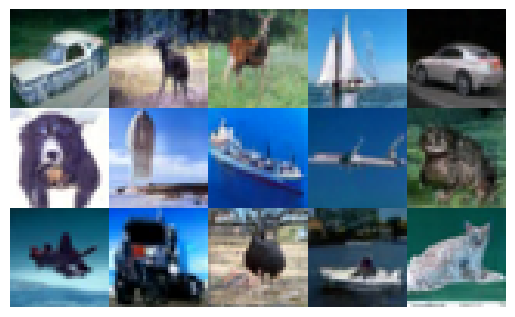

In [13]:
import matplotlib.pyplot as plt
from IPython.display import clear_output, display


n_samples = 15
s = 50
img_size = 32
device = "cuda"

xt = torch.randn(n_samples, 3, img_size, img_size).to(device)

for i in reversed(range(timesteps)):
    t = torch.tensor([i] * n_samples, device=device)
    t_float = t.float() / timesteps
    
    with torch.no_grad():
        eps_pred = uNet(xt, t)
    
    alpha_t = alpha[i]
    alpha_bar_t = alpha_bar[i]
    beta_t = beta[i]

    mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

    xt_for_grad = xt.detach().requires_grad_(True)

    xt_flat = xt_for_grad.reshape(-1, 3072)

    xt_centred = xt_flat - mean_pca.cuda()
    xt_pca = xt_centred @ components.cuda()
    
    ratio = (xt_pca @ theta)
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    
    guide_score = torch.autograd.grad(log_r.sum(), xt_for_grad)[0]
    
    mean = mean + s * beta_t * torch.tanh(guide_score)
    
    if i > 0:
        noise = torch.randn_like(xt)
        xt = mean + torch.sqrt(beta_t) * noise
    else:
        xt = mean

    if i % 20 == 0:
        xt_new = xt.cpu()
        img = torch.tensor([])
        for row in xt_new.split(5):
            img_row = torch.concat([row[i].permute(1,2,0) for i in range(row.shape[0])], dim =1).clamp(-1,1) * 0.5 + 0.5
            img = torch.cat([img, img_row])
        plt.imshow(img)
        plt.axis('off')
        plt.show()
    clear_output(wait=True)

In [235]:
torch.save(xt_any, 'xt_any.pt')
xt_any = torch.load('xt_any.pt')

(-0.5, 127.5, 127.5, -0.5)

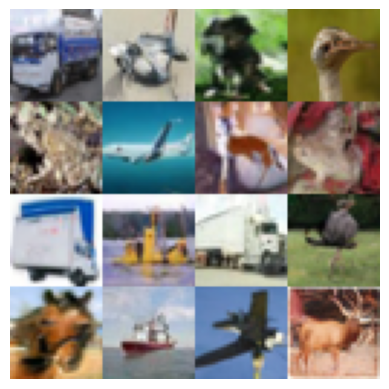

In [236]:
img = torch.tensor([])
for row in xt_new.split(4):
    img_row = torch.concat([row[i].permute(1,2,0) for i in range(row.shape[0])], dim =1).clamp(-1,1) * 0.5 + 0.5
    img = torch.cat([img, img_row])
plt.imshow(img)
plt.axis('off')

In [104]:
n_samples = 16
s = 1.5
final = []

with torch.no_grad():
    xt = torch.randn(n_samples, 3, img_size, img_size).to(device)
    
    for i in reversed(range(timesteps)):
        # print(i)
        t = torch.tensor([i] * n_samples, device=device)
        
        eps_pred = uNet(xt, t.long())
        
        alpha_t = alpha[i]
        alpha_bar_t = alpha_bar[i]
        beta_t = beta[i]

        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

        with torch.enable_grad():
            dre_xt = xt.detach().clone().requires_grad_(True)
            
            logits = standardClassifier(dre_xt, t/1000)
            log_probs = F.log_softmax(logits, dim=1)
            
            r = log_probs[:, 1] - log_probs[:, 0]
            
            guide_score = torch.autograd.grad(
                outputs=r.sum(),
                inputs=dre_xt
            )[0]
            
        mean = mean + s * beta_t * guide_score
        
        if i > 0:
            noise = torch.randn_like(xt)
            xt = mean + torch.sqrt(beta_t) * noise
        else:
            xt = mean
xt_con = xt.cpu()

In [238]:
# torch.save(xt_con, 'xt_con.pt')
xt_con = torch.load('xt_con.pt')

(-0.5, 127.5, 127.5, -0.5)

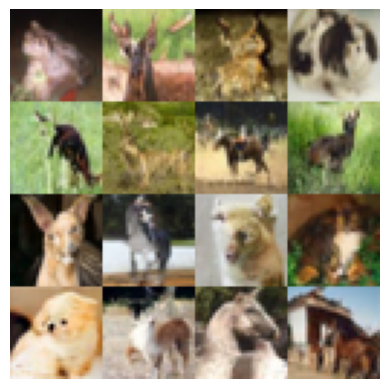

In [239]:
img = torch.tensor([])
for row in xt_con.split(4):
    img_row = torch.concat([row[i].permute(1,2,0) for i in range(row.shape[0])], dim =1).clamp(-1,1) * 0.5 + 0.5
    img = torch.cat([img, img_row])
plt.imshow(img)
plt.axis('off')

In [183]:
n_samples = 4
s = 0
final = []

xt_hist = []

snapshots = 10

snapshot_times = [25, 50, 100, 200, 500]
        
with torch.no_grad():
    xt = torch.randn(n_samples, 3, img_size, img_size).to(device)
    
    xt_hist.append(xt.cpu())

    for i in reversed(range(timesteps)):

        t = torch.tensor([i] * n_samples, device=device)
        
        eps_pred = uNet(xt, t.long())
        
        alpha_t = alpha[i]
        alpha_bar_t = alpha_bar[i]
        beta_t = beta[i]

        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

        with torch.enable_grad():
            dre_xt = xt.detach().clone().requires_grad_(True)
            
            logits = standardClassifier(dre_xt, t/1000)
            log_probs = F.log_softmax(logits, dim=1)
            
            r = log_probs[:, 1] - log_probs[:, 0]
            
            guide_score = torch.autograd.grad(
                outputs=r.sum(),
                inputs=dre_xt
            )[0]            
        
        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

        if i in snapshot_times:
            xt_hist.append(xt.cpu())

        mean = mean + s * beta_t * guide_score

        if i > 0:
            noise = torch.randn_like(xt)
            xt = mean + torch.sqrt(beta_t) * noise
        else:
            xt = mean

xt_hist.append(xt.cpu())

In [241]:
# torch.save(xt_hist, 'xt_hist.pt')
xt_hist = torch.load('xt_hist.pt')

In [242]:
images = []
for xt in xt_hist:
    img = torch.tensor([])
    for row in xt.cpu().split(2):
        img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).cpu()
        img = torch.cat([img, img_row], dim=-1)
    images.append((img.permute(1,2,0) * 0.5 + 0.5).clamp(0, 1))

In [243]:
new_images = [images[0]] + [images[1]] + [images[2]] + [images[4]] + [images[6]]

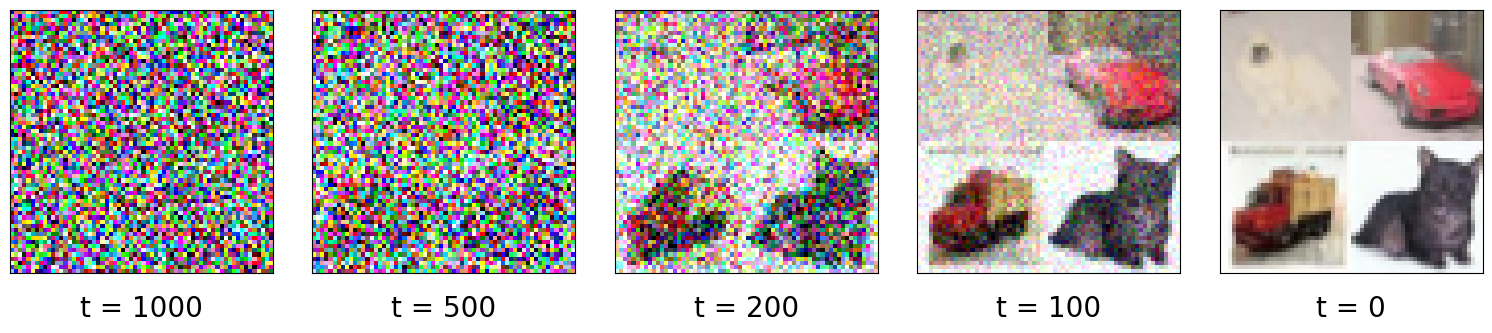

In [244]:
import matplotlib.pyplot as plt

n = len(new_images)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, new_images)):
    ax.imshow(img)

    # Remove ticks but keep clean frame spacing
    ax.set_xticks([])
    ax.set_yticks([])

    # Caption under plot
    ax.set_title(f"t = {([1000, 500, 200, 100, 0])[i]}", y=-0.2, fontsize=20)

# Better spacing between plots + room for captions
plt.subplots_adjust(wspace=0.15, bottom=0.25)

plt.show()

In [204]:
n_samples = 4
s = 1
final = []

xt_hist1 = []

snapshots = 10

snapshot_times = [25, 50, 100, 200, 500]
        
with torch.no_grad():
    xt = torch.randn(n_samples, 3, img_size, img_size).to(device)
    
    xt_hist1.append(xt.cpu())

    for i in reversed(range(timesteps)):

        t = torch.tensor([i] * n_samples, device=device)
        
        eps_pred = uNet(xt, t.long())
        
        alpha_t = alpha[i]
        alpha_bar_t = alpha_bar[i]
        beta_t = beta[i]

        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

        with torch.enable_grad():
            dre_xt = xt.detach().clone().requires_grad_(True)
            
            logits = standardClassifier(dre_xt, t/1000)
            log_probs = F.log_softmax(logits, dim=1)
            
            r = log_probs[:, 1] - log_probs[:, 0]
            
            guide_score = torch.autograd.grad(
                outputs=r.sum(),
                inputs=dre_xt
            )[0]            
        
        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

        if i in snapshot_times:
            xt_hist1.append(xt.cpu())

        mean = mean + s * beta_t * guide_score

        if i > 0:
            noise = torch.randn_like(xt)
            xt = mean + torch.sqrt(beta_t) * noise
        else:
            xt = mean

xt_hist1.append(xt.cpu())

In [246]:
# torch.save(xt_hist1, 'xt_hist1.pt')
xt_hist1 = torch.load('xt_hist.pt')

In [247]:
images1 = []
for xt in xt_hist1:
    img = torch.tensor([])
    for row in xt.cpu().split(2):
        img_row = torch.concat([row[i] for i in range(row.shape[0])], dim =1).cpu()
        img = torch.cat([img, img_row], dim=-1)
    images1.append((img.permute(1,2,0) * 0.5 + 0.5).clamp(0, 1))

In [248]:
new_images1 = [images1[0]] + [images1[1]] + [images1[2]] + [images1[4]] + [images1[6]]

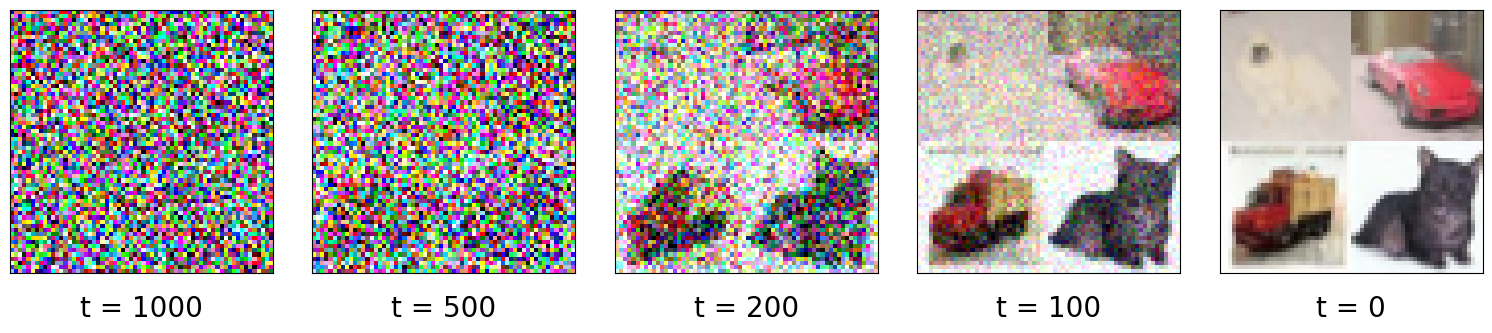

In [249]:
import matplotlib.pyplot as plt

n = len(new_images1)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, new_images1)):
    ax.imshow(img)

    # Remove ticks but keep clean frame spacing
    ax.set_xticks([])
    ax.set_yticks([])

    # Caption under plot
    ax.set_title(f"t = {([1000, 500, 200, 100, 0])[i]}", y=-0.2, fontsize=20)

# Better spacing between plots + room for captions
plt.subplots_adjust(wspace=0.15, bottom=0.25)

plt.show()